## PROVA PRATICA 2- FIT E DIAGNOSTICA

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import chi2


#1. importo da notebook 1
x = np.linspace(-5.0,5.0, 161) #array di posizioni

B = 20 #traslazione sulle y
I_0 = 400 #controlla l'altezza del massimo centrale
alpha = 0.9 #controlla la larghezza del massimo centrale
delta = 5.2 #controlla la distanza tra le frange

def mu(x, B, I_0, alpha, delta): 
    E = np.sinc(alpha*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B+I_0*E*C

#2.generazione di una acquisizione casuale, ovvero le ordinate, e le incertezze statistiche di Poisson
rng = np.random.default_rng(42)
y = rng.poisson(mu(x,B,I_0,alpha,delta))
sigma_y = np.where(y<1, 1, np.sqrt(y)) #errore minimo pari a 1

#3. Uniamo le 3 colonne in un'unica matrice
dati = np.column_stack ((x, y, sigma_y))

#4.creiamo il file csv
np.savetxt(
    "dati_fit.csv", 
    dati, 
    delimiter=";", 
    header="x;y;sigma_y", 
    comments=""
)





#### **Attività 1: caricamento e controllo dei dati**

Il numero di punti è: 161
L'intervallo delle x è: [np.float64(-5.0), np.float64(5.0)]
L'intervallo delle y è: [np.float64(13.0), np.float64(437.0)]
L'intervallo delle sigma_y è: [np.float64(3.605551275463989), np.float64(20.904544960366874)]


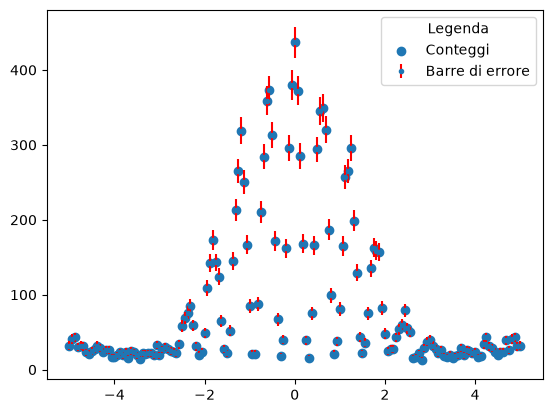

In [27]:
#1.caricamento del file.csv
dati = np.genfromtxt(
"dati_fit.csv",
delimiter=";",
names=True
)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

#2.si verifica che gli array abbiano la stessa lunghezza, contengano valori finiti, abbiano incertezze positive e posizioni ordinate
assert len(dati["x"]) == len(dati["y"]) == len(dati["sigma_y"]), "gli array hanno diversa lunghezza"
assert np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(sigma_y)), "gli array contengono valori non finiti"
assert np.all(sigma_y >0), "le incertezze sono negative"
assert np.all(x[:-1] <= x[1:]) or np.all(x[:-1] >= x[1:]), "Le posizioni non sono ordinate"

#3.stampare numero di punti, intervallo di x, intervallo di y, intervallo di sigma_y
print("Il numero di punti è:", len(x))
print("L'intervallo delle x è:", [min(x), max(x)])
print("L'intervallo delle y è:", [min(y), max(y)])
print("L'intervallo delle sigma_y è:", [min(sigma_y), max(sigma_y)])

#4.si rapprensenta il grafico con barre d'errore
fig, ax= plt.subplots()
estremi_bin=np.linspace(min(y),max(y),162)
plt.scatter(x, y, label='Conteggi')
plt.errorbar(x, y, yerr= sigma_y, xerr= None, ecolor="red", fmt='.', label='Barre di errore')
plt.legend(title='Legenda')


#### **Attività 2: Stime iniziali e bounds**

In [3]:
#1. stime iniziali
mask = ((x > -5) & (x < -2)) | ((x > 2) & (x < 5))
B0 = np.median(y[mask])
I0 = max(y) - B0
alpha0 = 0.4
delta0 = 10.5
print("Il fondo è:", B0)
print("Il massimo centrale è:", I0)
print("alfa è:", alpha0)
print ("delta è:", delta0)

#2.si impongono bounds positivi e abbastanza ampi
lower = [0.0, 0.0, 1e-5, 1e-5] # 3: alpha: La larghezza della busta (sinc) non può azzerarsi (evita divisioni per zero). 4:# delta: La frequenza delle frange (coseno) deve essere positiva e non nulla
upper = [np.inf, np.inf, np.inf, np.inf] # 3: alpha: Impedisce alla campana del sinc di diventare infinitamente stretta. 4:# delta: Impedisce alle oscillazioni di diventare infinitamente fitte (frequenza massima)

Il fondo è: 25.0
Il massimo centrale è: 412.0
alfa è: 0.4
delta è: 10.5


#### **Attività 3: Fit pesato**

B0= 27.3979 +- 0.5308
I0= 83.7473 +- 2.8182
alpha0= 0.8762 +- 0.0233
delta0= 12.9503 +- 0.0227

Matrice di correlazione.
[[ 1.    -0.289  0.244 -0.018]
 [-0.289  1.     0.397  0.024]
 [ 0.244  0.397  1.     0.004]
 [-0.018  0.024  0.004  1.   ]]


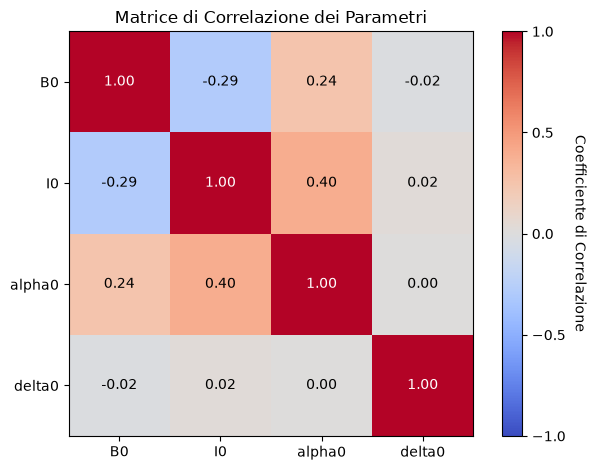

In [4]:
#1.fit 
popt, pcov = curve_fit(
mu, x, y,
p0= [B0,I0, alpha0, delta0],
sigma=sigma_y,
absolute_sigma=True,
bounds=(lower, upper),
maxfev=100000
)

#2.incertezze standard e matrice di correlazione
perr = np.sqrt(np.diag(pcov))
parametri_nome= ["B0","I0", "alpha0", "delta0"]
for nome, valore, errore in zip(parametri_nome, popt, perr):
    print(f"{nome}= {valore:.4f} +- {errore:.4f}")


#Creiamo la matrice facendo il prodotto esterno delle deviazioni standard d_i * d_j e dividiamo la matrice di covarianza pcov elemento per elemento
corr_matrix = pcov / np.outer(perr, perr)

print("\nMatrice di correlazione.")
print(np.round(corr_matrix, 3)) # Formattiamo la stampa per renderla leggibile come una matrice

#3.mappa di colore
fig, ax = plt.subplots()

# 2. Disegniamo la mappa di colore
# vmin e vmax fissano la scala da -1 a 1 (il range della correlazione)
# 'coolwarm' colora il positivo di rosso, il negativo di blu e lo 0 di bianco
cax = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# 3. Aggiungiamo la barra del colore laterale (Colorbar)
cbar = fig.colorbar(cax, ticks=[-1, -0.5, 0, 0.5, 1])
cbar.set_label('Coefficiente di Correlazione', rotation=270, labelpad=15)

# 4. Impostiamo i nomi dei parametri sugli assi
parametri_nome = ["B0", "I0", "alpha0", "delta0"]
ax.set_xticks(range(len(parametri_nome)))
ax.set_yticks(range(len(parametri_nome)))
ax.set_xticklabels(parametri_nome)
ax.set_yticklabels(parametri_nome)

# 5. Scriviamo i valori numerici dentro i quadratini per leggerli meglio
for i in range(len(parametri_nome)):
    for j in range(len(parametri_nome)):
        ax.text(j, i, f"{corr_matrix[i, j]:.2f}", 
                ha="center", va="center", 
                color="black" if abs(corr_matrix[i, j]) < 0.6 else "white")

ax.set_title("Matrice di Correlazione dei Parametri")
plt.tight_layout()
plt.show()




#### **Attività 4: Diagnostica  del fit**

  x    residuo   residuo/sigma
-5.0   +4.1467       +0.7330
-4.9  +12.8430       +2.0057
-4.9  +12.1772       +1.8570
-4.8   -0.1779       -0.0325
-4.8   +4.3826       +0.7747
-4.7   +2.6646       +0.4786
-4.6   -7.4493       -1.5533
-4.6   -8.4211       -1.8376
-4.5   -2.4656       -0.4931
-4.4   -1.3403       -0.2579
-4.4   +2.3101       +0.4084
-4.3   +0.3894       +0.0723
-4.2   -3.4047       -0.6950
-4.2   -2.1283       -0.4174
-4.1   -2.7269       -0.5348
-4.1  -10.9302       -2.6510
-4.0  -10.3990       -2.5221
-3.9   -8.7605       -2.0098
-3.9   -4.8524       -1.0118
-3.8   -8.5133       -1.9531
-3.8   -3.4007       -0.6942
-3.7  -11.4397       -2.8599
-3.6   -2.4076       -0.4815
-3.6   -4.3990       -0.9173
-3.5   -8.4005       -1.9272
-3.4  -13.5122       -3.6113
-3.4   -5.6961       -1.2144
-3.3   -6.5198       -1.4227
-3.2   -5.4854       -1.1695
-3.2   -6.4256       -1.3699
-3.1   -9.8931       -2.2696
-3.1   +5.2727       +0.9179
-3.0   -8.8814       -2.0375
-2.9   -3.64

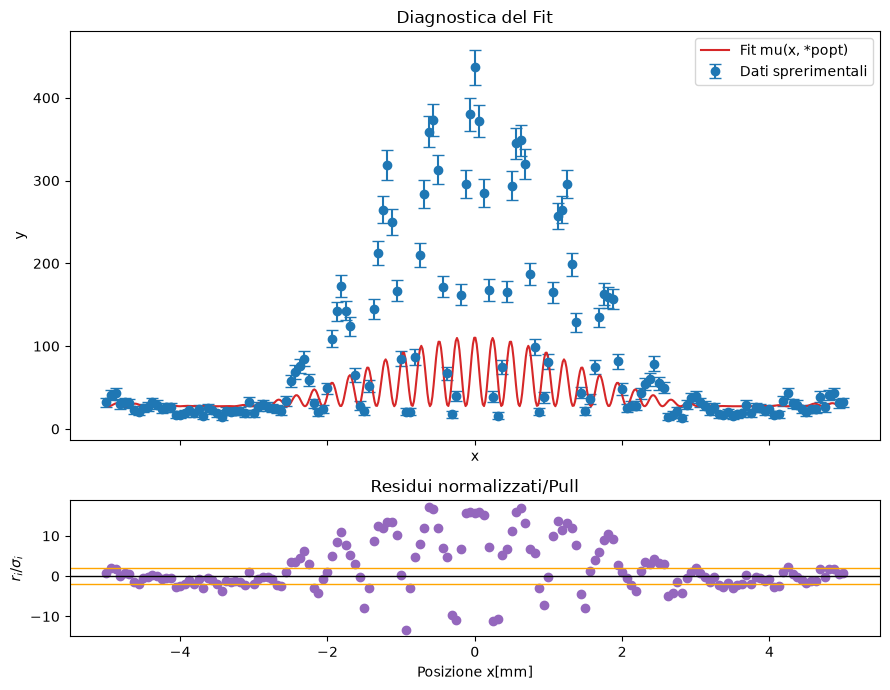

In [5]:

#Calcolo dei residui, dei pull normalizzati, del chi quadro, dei gradi di libertà e del chi quadro ridotto

y_fit = mu(x, *popt)
residuals = y - y_fit
normalized_residuals = residuals / sigma_y
chi2_val = np.sum(normalized_residuals**2)  # somma degli p_i^2
ndf = len(x) - 4
chi2_red = chi2_val / ndf
p_value = chi2.sf(chi2_val, ndf)

#2.si stampano i valori utili
print("  x    residuo   residuo/sigma")
for xi, ri, zi in zip(x, residuals, normalized_residuals):
    print(f"{xi:4.1f}  {ri:+8.4f}      {zi:+8.4f}")
print(f"\nchi² = {chi2_val:.4f}")
print(f"gradi di libertà = {ndf}")
print(f"chi² ridotto = {chi2_red:.4f}")
print(f"p-value = {p_value:.4f})")

#3. Dati e fit (sopra) + e Pulls (sotto)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex= True, gridspec_kw={'height_ratios':[3,1]})
x_plot = np.linspace(x.min(), x.max(), 600) #600 è il numero scelto per avere un dominio più denso rispetto ai nostri 120 punti sperimentali
y_plot = mu(x_plot, *popt)

axes[0].errorbar(x, y, yerr=sigma_y, fmt="o", capsize=4, label="Dati sprerimentali")
axes[0].plot(x_plot, y_plot, color="tab:red", label="Fit mu(x, *popt)")
axes[0].set(xlabel="x", ylabel="y", title="Diagnostica del Fit")
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(-2, color="orange", linewidth=1)
axes[1].axhline(2, color="orange", linewidth=1)
axes[1].scatter(x, normalized_residuals, color="tab:purple")
axes[1].set(xlabel="Posizione x[mm]", ylabel=r"$r_i/\sigma_i$", title="Residui normalizzati/Pull")

plt.tight_layout()
plt.show()


#### **Attività 5 Confronto con un modello incompleto (opzionale)**

  x    residuo ridotto   residuo ridotto/sigma ridotto
-5.0  +113.3797       +8.0373
-4.9  +238.7824      +13.0461
-4.9  +320.4411      +15.6921
-4.8  +302.8963      +15.3575
-4.8  +261.5906      +14.1246
-4.7  +147.0897       +9.5545
-4.6   +7.8562       +0.7631
-4.6  -62.0708      -11.1482
-4.5  -46.7253       -7.7875
-4.4  +32.5090       +3.0184
-4.4  +149.8447       +9.5928
-4.3  +249.1704      +13.3762
-4.2  +302.3050      +15.2882
-4.2  +309.7824      +15.6664
-4.1  +224.7609      +12.7246
-4.1  +72.7765       +5.5817
-4.0  -28.3588       -3.4646
-3.9  -64.5982      -14.4446
-3.9  -28.9827       -3.9811
-3.8  +67.3455       +5.3408
-3.8  +169.7033      +10.3663
-3.7  +298.6097      +15.1207
-3.6  +318.1273      +15.9064
-3.6  +312.1834      +15.6680
-3.5  +188.4402      +11.1819
-3.4  +47.9113       +3.9788
-3.4  -46.9821       -7.4285
-3.3  -58.2454      -12.1450
-3.2  -12.9636       -1.4870
-3.2  +95.0863       +6.8445
-3.1  +222.0783      +12.4929
-3.1  +299.6904      +15.3135

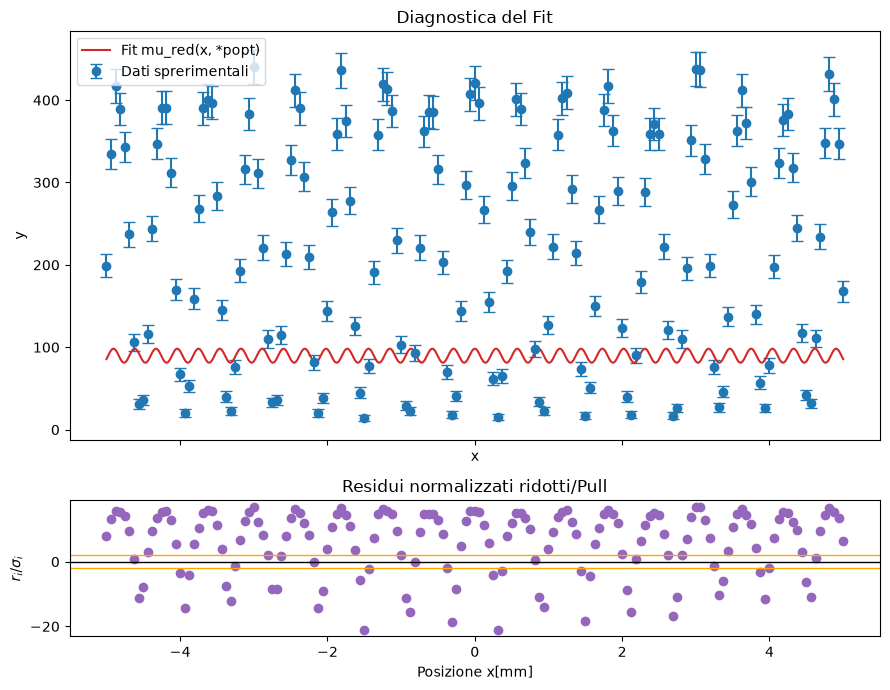

In [15]:
#1. importo da notebook 1
x = np.linspace(-5.0,5.0, 161) #array di posizioni

B = 20 #traslazione sulle y
I_0 = 400 #controlla l'altezza del massimo centrale
delta = 5.2 #controlla la distanza tra le frange

def mu_red(x, B, I_0, delta): 
    C = np.cos(delta*x)**2
    return B+I_0*C

#2.generazione di una acquisizione casuale, ovvero le ordinate, e le incertezze statistiche di Poisson
rng = np.random.default_rng(42)
y_red = rng.poisson(mu_red(x,B,I_0,delta))
sigma_y_red = np.where(y_red<1, 1, np.sqrt(y_red)) #errore minimo pari a 1

#3. Uniamo le 3 colonne in un'unica matrice
dati = np.column_stack ((x, y_red, sigma_y_red))

#bounds nuovi
lower_red = [0.0, 0.0, 1e-5] # 3: alpha: La larghezza della busta (sinc) non può azzerarsi (evita divisioni per zero). 4:# delta: La frequenza delle frange (coseno) deve essere positiva e non nulla
upper_red = [np.inf, np.inf, np.inf]

#1.fit 
popt, pcov = curve_fit(
mu_red, x, y,
p0= [B0,I0, delta0],
sigma=sigma_y_red,
absolute_sigma=True,
bounds=(lower_red, upper_red),
maxfev=100000
)

#Calcolo dei residui, dei pull normalizzati, del chi quadro, dei gradi di libertà e del chi quadro ridotto
y_fit_red = mu_red(x, *popt)
residuals_red = y_red - y_fit_red
normalized_residuals_red = residuals_red / sigma_y_red
chi2_val_red = np.sum(normalized_residuals_red**2)  # somma degli p_i^2
ndf_red = len(x) - 4
chi2_red_2 = chi2_val_red / ndf_red
p_value_red = chi2.sf(chi2_val_red, ndf_red)

#2.si stampano i valori utili
print("  x    residuo ridotto   residuo ridotto/sigma ridotto")
for xi, ri, zi in zip(x, residuals_red, normalized_residuals_red):
    print(f"{xi:4.1f}  {ri:+8.4f}      {zi:+8.4f}")
print(f"\nchi² = {chi2_val_red:.4f}")
print(f"gradi di libertà = {ndf_red}")
print(f"chi² ridotto = {chi2_red_2:.4f}")
print(f"p-value = {p_value_red:.4f})")

#3. Dati e fit (sopra) + e Pulls (sotto)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex= True, gridspec_kw={'height_ratios':[3,1]})
x_plot = np.linspace(x.min(), x.max(), 600) #600 è il numero scelto per avere un dominio più denso rispetto ai nostri 120 punti sperimentali
y_plot = mu_red(x_plot, *popt)

axes[0].errorbar(x, y, yerr=sigma_y, fmt="o", capsize=4, label="Dati sprerimentali")
axes[0].plot(x_plot, y_plot, color="tab:red", label="Fit mu_red(x, *popt)")
axes[0].set(xlabel="x", ylabel="y", title="Diagnostica del Fit")
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(-2, color="orange", linewidth=1)
axes[1].axhline(2, color="orange", linewidth=1)
axes[1].scatter(x, normalized_residuals_red, color="tab:purple")
axes[1].set(xlabel="Posizione x[mm]", ylabel=r"$r_i/\sigma_i$", title="Residui normalizzati ridotti/Pull")

plt.tight_layout()
plt.show()

Con il modello incompleto il pull plot del modello segue la funzione coseno, e nel grafico del fit i punti sono più disparati mentre se ci fosse l'inviluppo sarebbero più schiacciati verso il centro.

#### **Attività 6 Controllo di stabilità (opzionale)**

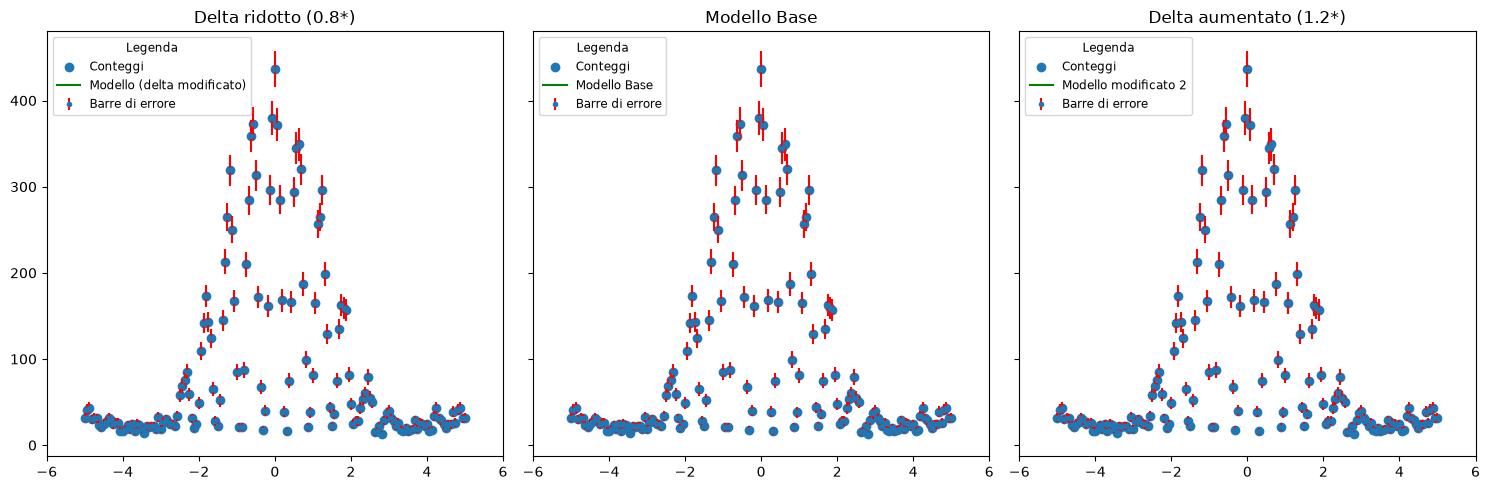

In [37]:
estremi_bin=np.linspace(min(y),max(y),162)

y_curva_1 = mu(estremi_bin, B, I_0, alpha, delta=0.8 * 5.2)
y_curva_base = mu(estremi_bin, B, I_0, alpha, delta)
y_curva_2 = mu(estremi_bin, B, I_0, alpha, delta=1.2 * 5.2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

# --- GRAFICO 1 (Sinistra): Delta = 0.8 * 5.2 ---
axes[0].scatter(x, y, label="Conteggi")
axes[0].errorbar(
    x, y, yerr=sigma_y, xerr=None, ecolor="red", fmt=".", label="Barre di errore"
)
axes[0].plot(
    estremi_bin, y_curva_1, color="green", label="Modello (delta modificato)"
)
axes[0].set_xlim(-6.0, 6.0)
axes[0].set_title("Delta ridotto (0.8*)")
axes[0].legend(
    title="Legenda", loc="upper left", fontsize="small", title_fontsize="small"
)

# --- GRAFICO 2 (Centro): Modello Base ---
axes[1].scatter(x, y, label="Conteggi")
axes[1].errorbar(
    x, y, yerr=sigma_y, xerr=None, ecolor="red", fmt=".", label="Barre di errore"
)
axes[1].plot(estremi_bin, y_curva_base, color="green", label="Modello Base")
axes[1].set_xlim(-6.0, 6.0)
axes[1].set_title("Modello Base")
axes[1].legend(
    title="Legenda", loc="upper left", fontsize="small", title_fontsize="small"
)


# --- GRAFICO 3 (Destra): Delta = 1.2 * 5.2 ---
axes[2].scatter(x, y, label="Conteggi")
axes[2].errorbar(
    x, y, yerr=sigma_y, xerr=None, ecolor="red", fmt=".", label="Barre di errore"
)
axes[2].plot(
    estremi_bin, y_curva_2, color="green", label="Modello modificato 2"
)
axes[2].set_xlim(-6.0, 6.0)
axes[2].set_title("Delta aumentato (1.2*)")
axes[2].legend(
    title="Legenda", loc="upper left", fontsize="small", title_fontsize="small"
)

# Mostra l'intera figura con i 3 grafici affiancati
plt.tight_layout()
plt.show()


